<figure><center>
<img src='https://www.economicas.uba.ar/wp-content/uploads/2020/08/cropped-logo_FCE.png''/>
</center></figure>

# Transformación de Variables

La transformación de variables (también llamada *feature engineering*) prepara los datos antes de entrenar un modelo.

En esta notebook vemos las transformaciones más comunes:
1. Escalado de variables numéricas (Min-Max, Z-score, Robust)
2. Transformación de distribución (Box-Cox)
3. Numérica → Categórica (Binning con `pd.cut` y `pd.qcut`)
4. Categórica → Numérica (One-Hot Encoding)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, PowerTransformer

---
## Dataset — Empleados

Generamos un dataset sintético de 500 empleados con el que trabajaremos en todas las secciones.

In [2]:
np.random.seed(42)
n = 500

categorias = ['Junior', 'Semi', 'Senior', 'Lead']

df = pd.DataFrame({
    'edad':        np.clip(np.random.normal(35, 8, n), 22, 65).round().astype(int),
    'antiguedad':  np.round(np.random.exponential(scale=4, size=n), 1),  # sesgada a la derecha
    'salario':     np.clip(np.random.normal(150_000, 40_000, n), 50_000, 400_000).round(-3),
    'mes_ingreso': np.random.randint(1, 13, n),
    'categoria':   np.random.choice(categorias, size=n, p=[0.35, 0.30, 0.25, 0.10]),
})

df.head()

,edad,antiguedad,salario,mes_ingreso,categoria
0,39,4.2,143000.0,8,Lead
1,34,3.4,156000.0,3,Lead
2,40,1.8,198000.0,8,Senior
3,47,17.2,117000.0,1,Junior
4,33,3.7,165000.0,5,Senior


In [ ]:
df.describe().round(1)

---
## 1. Escalado de variables numéricas

Escalar transforma los valores numéricos a un rango común **sin cambiar la forma de la distribución**.

Es necesario cuando las variables tienen unidades o magnitudes muy distintas:
- Algoritmos basados en distancias (KNN, K-Means) tratan igual a todas las variables — si `salario` va de 50k a 400k y `edad` va de 22 a 65, el salario domina la distancia artificialmente.
- Regresiones con regularización (Ridge, Lasso) penalizan los coeficientes por igual — variables en distinta escala reciben penalizaciones injustas.

### Min-Max

Escala todos los valores al intervalo [0, 1]:

$$x_{\text{norm}} = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

El mínimo original pasa a ser 0, el máximo pasa a ser 1, y el resto se distribuye proporcionalmente.

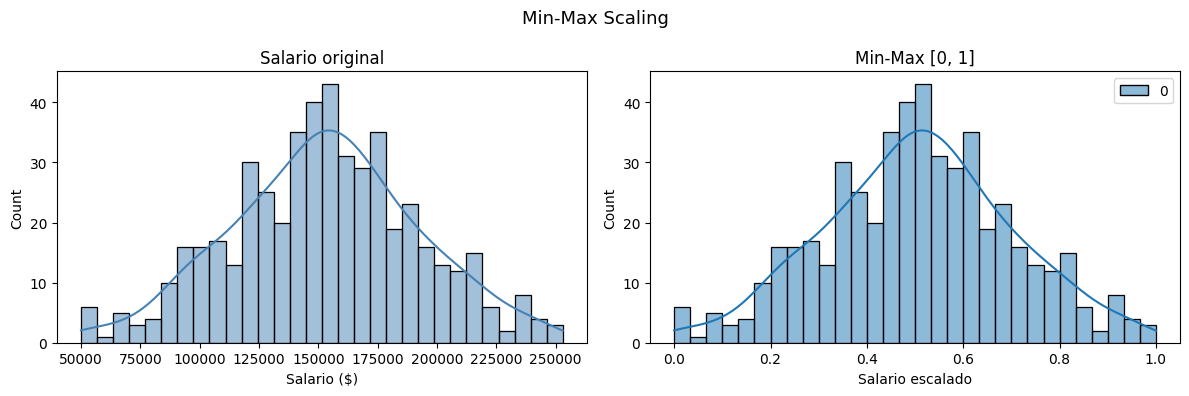

In [3]:
scaler_mm = MinMaxScaler()
salario_mm = scaler_mm.fit_transform(df[['salario']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['salario'], bins=30, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Salario original')
axes[0].set_xlabel('Salario ($)')

sns.histplot(salario_mm, bins=30, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title('Min-Max [0, 1]')
axes[1].set_xlabel('Salario escalado')

plt.suptitle('Min-Max Scaling', fontsize=13)
plt.tight_layout()
plt.show()

### Z-score (StandardScaler)

Centra los datos en 0 y los escala por desvío estándar:

$$Z = \frac{x - \mu}{\sigma}$$

El resultado no tiene rango fijo — puede tomar valores negativos o mayores que 1.

**Sensible a outliers**: un valor extremo desplaza la media y comprime todos los demás valores hacia el centro.

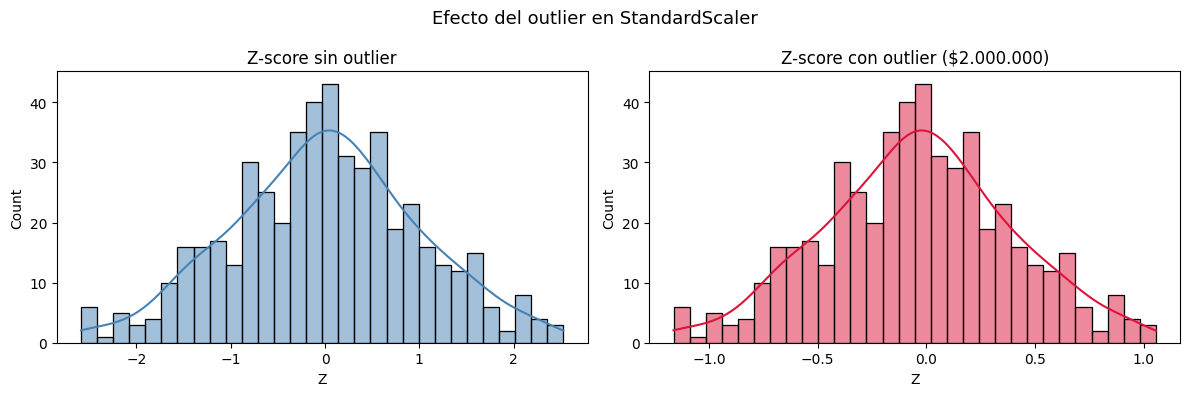

In [4]:
# Agregamos un outlier extremo para mostrar el efecto
salario_con_outlier = np.append(df['salario'].values, 2_000_000)

scaler_std = StandardScaler()
sin_out = scaler_std.fit_transform(df[['salario']]).flatten()
con_out = scaler_std.fit_transform(salario_con_outlier.reshape(-1, 1)).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(sin_out, bins=30, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Z-score sin outlier')
axes[0].set_xlabel('Z')

sns.histplot(con_out[:-1], bins=30, kde=True, color='crimson', ax=axes[1])
axes[1].set_title('Z-score con outlier ($2.000.000)')
axes[1].set_xlabel('Z')

plt.suptitle('Efecto del outlier en StandardScaler', fontsize=13)
plt.tight_layout()
plt.show()

### RobustScaler

Usa la **mediana** y el **IQR** en lugar de media y desvío:

$$X_{\text{escalada}} = \frac{X - \text{mediana}(X)}{Q3(X) - Q1(X)}$$

Al no depender de los extremos, el outlier no distorsiona el resultado.

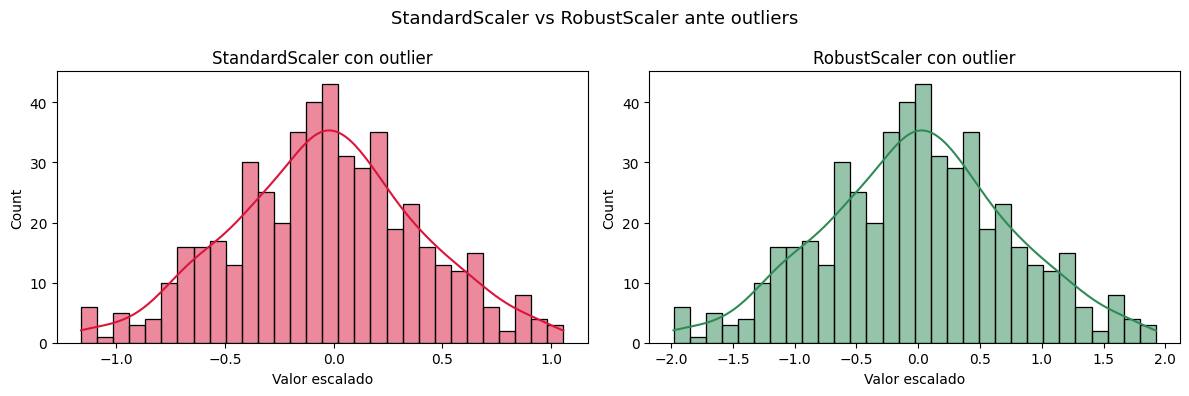

In [5]:
scaler_rob = RobustScaler()
robust_out = scaler_rob.fit_transform(salario_con_outlier.reshape(-1, 1)).flatten()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(con_out[:-1], bins=30, kde=True, color='crimson', ax=axes[0])
axes[0].set_title('StandardScaler con outlier')
axes[0].set_xlabel('Valor escalado')

sns.histplot(robust_out[:-1], bins=30, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title('RobustScaler con outlier')
axes[1].set_xlabel('Valor escalado')

plt.suptitle('StandardScaler vs RobustScaler ante outliers', fontsize=13)
plt.tight_layout()
plt.show()

---
## 2. Transformación de distribución — Box-Cox

Algunas variables tienen distribución asimétrica (sesgada). Muchos modelos asumen normalidad, por lo que conviene transformar la variable antes de usarla.

Box-Cox busca el λ óptimo que hace la distribución lo más normal posible:

$$y(\lambda) = \begin{cases} \frac{y^\lambda - 1}{\lambda} & \text{si } \lambda \neq 0 \\ \ln(y) & \text{si } \lambda = 0 \end{cases}$$

Casos especiales:
- λ = 0 → transformación logarítmica
- λ = 0.5 → raíz cuadrada  
- λ = 1 → sin transformación

**Requisito**: todos los valores deben ser positivos.

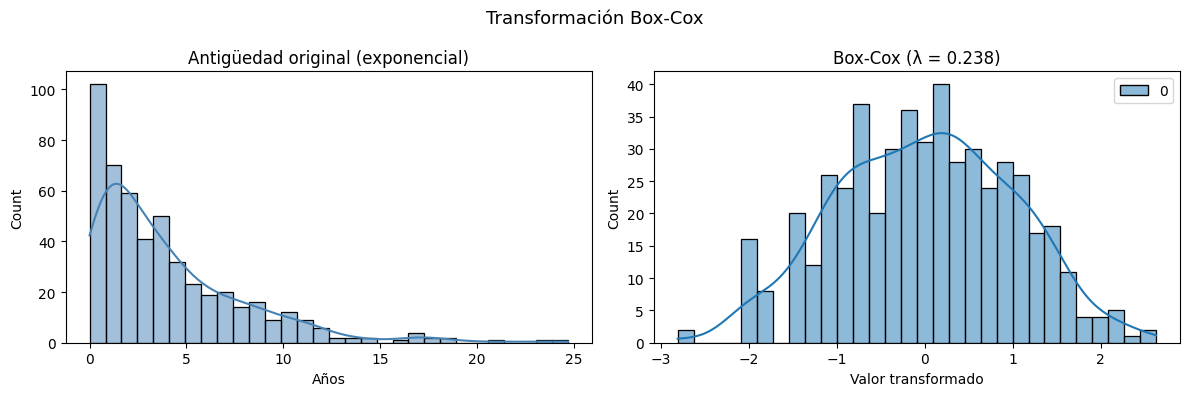

λ óptimo encontrado: 0.238


In [6]:
# antiguedad tiene distribución exponencial — sesgada a la derecha
# es el candidato natural para Box-Cox en nuestro dataset

transformer = PowerTransformer(method='box-cox')
antiguedad_bc = transformer.fit_transform(df[['antiguedad']] + 0.01)  # +0.01 por si hay ceros

lambda_optimo = transformer.lambdas_[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['antiguedad'], bins=30, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Antigüedad original (exponencial)')
axes[0].set_xlabel('Años')

sns.histplot(antiguedad_bc, bins=30, kde=True, color='seagreen', ax=axes[1])
axes[1].set_title(f'Box-Cox (λ = {lambda_optimo:.3f})')
axes[1].set_xlabel('Valor transformado')

plt.suptitle('Transformación Box-Cox', fontsize=13)
plt.tight_layout()
plt.show()

print(f'λ óptimo encontrado: {lambda_optimo:.3f}')

---
## 3. Numérica → Categórica: Binning

Agrupa valores continuos en intervalos discretos (bins).
Útil para reducir el efecto de outliers o cuando el modelo necesita variables categóricas.

Dos estrategias:
- `pd.cut` → bins de **igual ancho**
- `pd.qcut` → bins de **igual frecuencia** (por cuartiles)

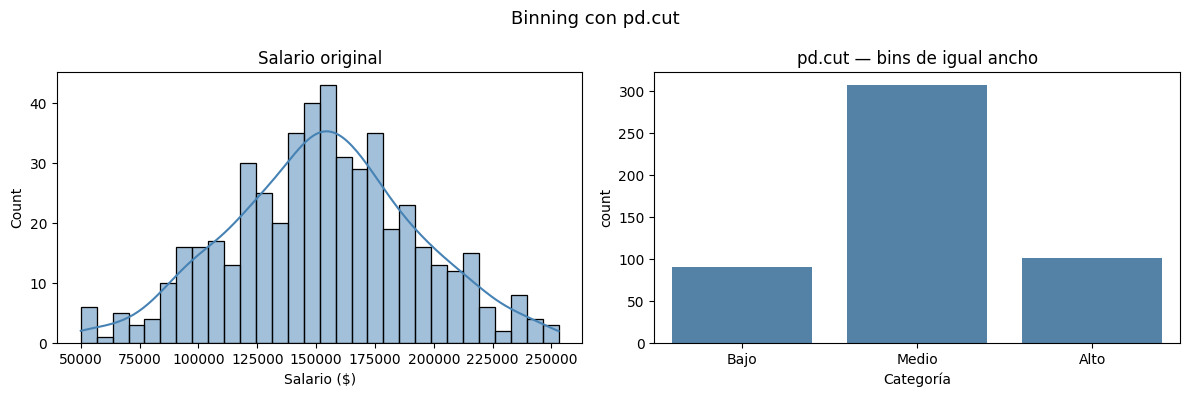

In [7]:
# Bins de igual ancho: el rango total se divide en 3 partes iguales
df['salario_cut'] = pd.cut(
    df['salario'],
    bins=3,
    labels=['Bajo', 'Medio', 'Alto']
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['salario'], bins=30, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Salario original')
axes[0].set_xlabel('Salario ($)')

sns.countplot(x='salario_cut', data=df, order=['Bajo', 'Medio', 'Alto'],
              color='steelblue', ax=axes[1])
axes[1].set_title('pd.cut — bins de igual ancho')
axes[1].set_xlabel('Categoría')

plt.suptitle('Binning con pd.cut', fontsize=13)
plt.tight_layout()
plt.show()

Con `pd.cut` los intervalos tienen el mismo ancho, pero si la distribución no es uniforme algunos bins quedan casi vacíos.

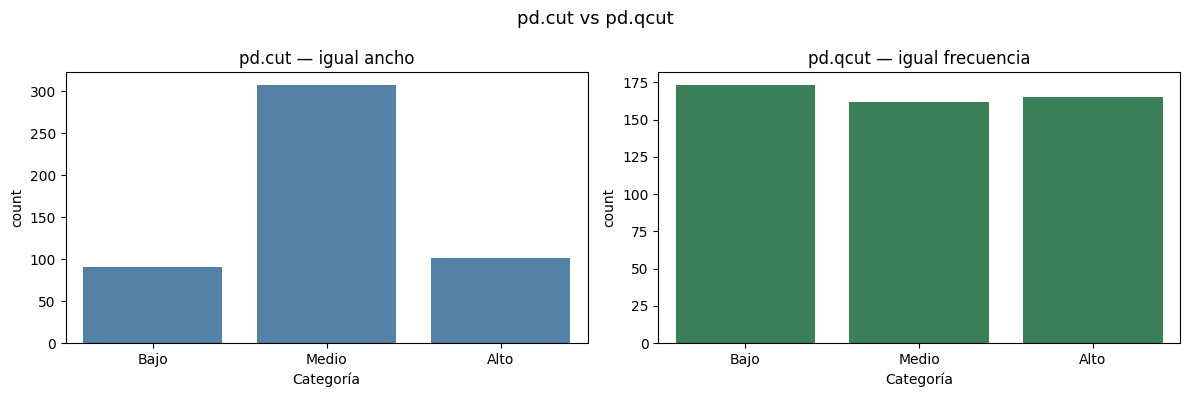

In [8]:
# Bins de igual frecuencia: cada bin tiene aproximadamente el mismo número de filas
df['salario_qcut'] = pd.qcut(
    df['salario'],
    q=3,
    labels=['Bajo', 'Medio', 'Alto']
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x='salario_cut', data=df, order=['Bajo', 'Medio', 'Alto'],
              color='steelblue', ax=axes[0])
axes[0].set_title('pd.cut — igual ancho')
axes[0].set_xlabel('Categoría')

sns.countplot(x='salario_qcut', data=df, order=['Bajo', 'Medio', 'Alto'],
              color='seagreen', ax=axes[1])
axes[1].set_title('pd.qcut — igual frecuencia')
axes[1].set_xlabel('Categoría')

plt.suptitle('pd.cut vs pd.qcut', fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
# pd.qcut permite inspeccionar los límites reales de cada bin
_, limites = pd.qcut(df['salario'], q=3, retbins=True)

print('Límites de los bins (pd.qcut):')
for i, (a, b) in enumerate(zip(limites, limites[1:])):
    print(f'  Bin {i+1}: ${a:,.0f} — ${b:,.0f}')

Límites de los bins (pd.qcut):
  Bin 1: $50,000 — $138,000
  Bin 2: $138,000 — $168,000
  Bin 3: $168,000 — $253,000


---
## 4. Categórica → Numérica: One-Hot Encoding

Los modelos de machine learning no pueden trabajar con texto directamente.
One-Hot Encoding convierte cada categoría en una columna binaria (0 o 1).

Con **k** categorías se crean **k** columnas — una por cada valor posible.

In [10]:
# pd.get_dummies es la forma más directa en pandas
dummies = pd.get_dummies(df['categoria'], prefix='cat')

# Mostramos las primeras filas junto a la columna original
pd.concat([df[['categoria']], dummies], axis=1).head(10)

,categoria,cat_Junior,cat_Lead,cat_Semi,cat_Senior
0,Lead,False,True,False,False
1,Lead,False,True,False,False
2,Senior,False,False,False,True
3,Junior,True,False,False,False
4,Senior,False,False,False,True
5,Junior,True,False,False,False
6,Junior,True,False,False,False
7,Senior,False,False,False,True
8,Junior,True,False,False,False
9,Semi,False,False,True,False


### Dummy trap — `drop_first=True`

Con **k** categorías alcanza con **k-1** columnas: la categoría faltante se infiere cuando todas las demás son 0.

Incluir las **k** columnas genera **multicolinealidad perfecta**, lo que rompe modelos de regresión.

In [11]:
dummies_sin_trampa = pd.get_dummies(df['categoria'], prefix='cat', drop_first=True)

print('Con drop_first=False:', pd.get_dummies(df['categoria'], prefix='cat').columns.tolist())
print('Con drop_first=True: ', dummies_sin_trampa.columns.tolist())
print()
print("La categoría ausente es 'Junior' — se infiere cuando cat_Lead=cat_Semi=cat_Senior=0")

Con drop_first=False: ['cat_Junior', 'cat_Lead', 'cat_Semi', 'cat_Senior']
Con drop_first=True:  ['cat_Lead', 'cat_Semi', 'cat_Senior']

La categoría ausente es 'Junior' — se infiere cuando cat_Lead=cat_Semi=cat_Senior=0


In [12]:
# Incorporamos las dummies al dataset
df_encoded = pd.concat([df, dummies_sin_trampa], axis=1)

print(f'Columnas originales:    {df.shape[1]}')
print(f'Columnas con dummies:   {df_encoded.shape[1]}')
df_encoded.head()

Columnas originales:    7
Columnas con dummies:   10


,edad,antiguedad,salario,mes_ingreso,categoria,salario_cut,salario_qcut,cat_Lead,cat_Semi,cat_Senior
0,39,4.2,143000.0,8,Lead,Medio,Medio,True,False,False
1,34,3.4,156000.0,3,Lead,Medio,Medio,True,False,False
2,40,1.8,198000.0,8,Senior,Alto,Alto,False,False,True
3,47,17.2,117000.0,1,Junior,Bajo,Bajo,False,False,False
4,33,3.7,165000.0,5,Senior,Medio,Medio,False,False,True


---
## Resumen

| Transformación | Función / Clase | Cuándo usarla |
|---|---|---|
| Min-Max | `MinMaxScaler` | Cuando necesitás rango fijo [0,1] y no hay outliers |
| Z-score | `StandardScaler` | Datos sin outliers extremos |
| Robust | `RobustScaler` | Datos con outliers |
| Box-Cox | `PowerTransformer` | Variable sesgada que necesita normalización |
| Binning igual ancho | `pd.cut` | Categorías de igual rango |
| Binning igual frecuencia | `pd.qcut` | Categorías con igual cantidad de datos |
| One-Hot Encoding | `pd.get_dummies` | Variable categórica → columnas binarias |